# Comparison of Spatial Interpolation Methods: Diffusion vs. Ordinary Kriging

This notebook provides a step-by-step comparison between two spatial interpolation techniques:
1. **Diffusion Interpolation**: A physics-based method that iteratively applies a discrete Laplacian operator to generate a smooth surface.
2. **Ordinary Kriging**: A geostatistical method that uses a variogram to model spatial correlation, estimating values while also producing a measurement of interpolation uncertainty (variance).

## 1. Dependencies & Setup
Import required libraries including NumPy, Matplotlib, SciPy for the convolution, and PyKrige for Ordinary Kriging.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve
from pykrige.ok import OrdinaryKriging

# Set plot style
plt.style.use('default')

## 2. Generate Synthetic Data
We create a true surface on a 50x50 grid by combining several Gaussian peaks to form interesting topology. Then, we randomly sample approximately 5-10% of these grid points to act as our sparse observed dataset. The unobserved points will be treated as `NaN`.

In [2]:
np.random.seed(42)

# Grid dimensions
grid_size = 50
x = np.linspace(0, 10, grid_size)
y = np.linspace(0, 10, grid_size)
X, Y = np.meshgrid(x, y)

# Create a true surface combining Gaussian peaks
def gaussian_peak(x, y, x0, y0, sigma, amplitude):
    return amplitude * np.exp(-((x - x0)**2 + (y - y0)**2) / (2 * sigma**2))

true_surface = (
    gaussian_peak(X, Y, 3, 3, 2, 10) +
    gaussian_peak(X, Y, 7, 8, 1.5, 7) +
    gaussian_peak(X, Y, 8, 2, 2.5, -5) +
    gaussian_peak(X, Y, 5, 5, 4, 3)
)

# Simulate sparse sampling (randomly select 5% of points)
sampling_rate = 0.05
mask = np.random.rand(grid_size, grid_size) < sampling_rate
sparse_data = np.full(true_surface.shape, np.nan)
sparse_data[mask] = true_surface[mask]

print(f"Total grid points: {grid_size**2}")
print(f"Sampled points: {np.sum(mask)}")

Total grid points: 2500
Sampled points: 129


## 3. Implement Diffusion Interpolation
Here we simulate the diffusion equation (Laplace equation for steady state) by repeatedly convolving the grid with an averaging kernel (4-connected neighbors). At each iteration, we enforce the known boundary conditions (the sparse data points).

In [3]:
def diffusion_interpolation(sparse_grid, mask, iterations=1000):
    # Initialize the grid: replace NaNs with the mean of known values to speed up convergence
    mean_val = np.nanmean(sparse_grid)
    grid = np.copy(sparse_grid)
    grid[~mask] = mean_val
    
    # Simple discrete Laplacian kernel for 4-connected neighbors
    kernel = np.array([[0, 1, 0],
                       [1, 0, 1],
                       [0, 1, 0]]) / 4.0
    
    for _ in range(iterations):
        # Convolve to average neighbors
        new_grid = convolve(grid, kernel, mode='reflect')
        # Enforce known boundary conditions
        new_grid[mask] = sparse_grid[mask]
        grid = new_grid
        
    return grid

diffusion_result = diffusion_interpolation(sparse_data, mask, iterations=2000)

## 4. Implement Ordinary Kriging
We extract the valid non-NaN coordinates from our sparse data. We then fit an Ordinary Kriging model using a spherical variogram and estimate over the entire 50x50 grid. The model returns both the predicted values and the estimation variance.

In [4]:
# Extract coordinates and values of non-NaN sparse data points
grid_y_indices, grid_x_indices = np.where(mask)
x_sparse = x[grid_x_indices]
y_sparse = y[grid_y_indices]
z_sparse = sparse_data[mask]

# Define and execute Kriging using a spherical variogram model
OK = OrdinaryKriging(
    x_sparse, 
    y_sparse, 
    z_sparse, 
    variogram_model='spherical',
    verbose=False,
    enable_plotting=False
)

# Execute Kriging over the full grid
kriging_result, kriging_variance = OK.execute('grid', x, y)

# Convert from masked arrays to standard numpy arrays for plotting
kriging_result = kriging_result.data
kriging_variance = kriging_variance.data

## 5. Visualization and Comparison
We plot five panels arrayed in a single row to directly compare the True Surface, Sparse Data, Diffusion Interpolation Result, Kriging Result, and Kriging Variance. We utilize consistent color scaling to assure a fair visual baseline.

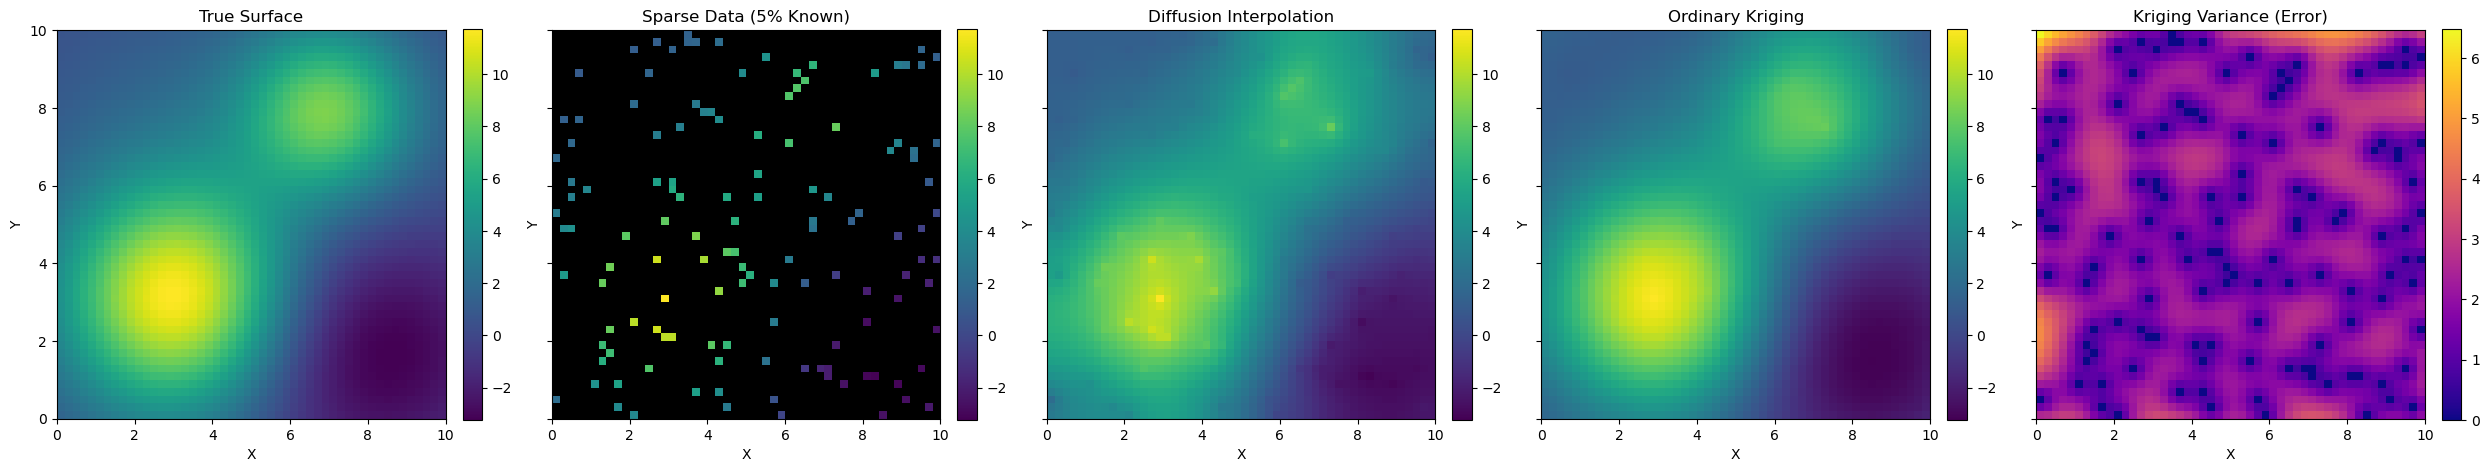

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(25, 4.5), sharex=True, sharey=True)

# Define a common color scale (vmin and vmax) for surface values
vmin = np.min(true_surface)
vmax = np.max(true_surface)

# Define a custom colormap specifically handling NaNs as a distinct background color (black)
cmap = plt.cm.viridis.copy()
cmap.set_bad(color='black')

# 1. True Surface
im0 = axes[0].imshow(true_surface, origin='lower', extent=[0, 10, 0, 10], 
                     cmap=cmap, vmin=vmin, vmax=vmax)
axes[0].set_title('True Surface', fontsize=12)
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# 2. Sparse Data
im1 = axes[1].imshow(sparse_data, origin='lower', extent=[0, 10, 0, 10], 
                     cmap=cmap, vmin=vmin, vmax=vmax)
axes[1].set_title('Sparse Data (5% Known)', fontsize=12)
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# 3. Diffusion Interpolation Result
im2 = axes[2].imshow(diffusion_result, origin='lower', extent=[0, 10, 0, 10], 
                     cmap=cmap, vmin=vmin, vmax=vmax)
axes[2].set_title('Diffusion Interpolation', fontsize=12)
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

# 4. Kriging Interpolation Result
im3 = axes[3].imshow(kriging_result, origin='lower', extent=[0, 10, 0, 10], 
                     cmap=cmap, vmin=vmin, vmax=vmax)
axes[3].set_title('Ordinary Kriging', fontsize=12)
fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

# 5. Kriging Variance Map (uses its own relative color scale)
im4 = axes[4].imshow(kriging_variance, origin='lower', extent=[0, 10, 0, 10], 
                     cmap='plasma')
axes[4].set_title('Kriging Variance (Error)', fontsize=12)
fig.colorbar(im4, ax=axes[4], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlabel('X')
    ax.set_ylabel('Y')

plt.tight_layout()
plt.show()

## 6. Summary
- **Diffusion Interpolation** typically acts like an iterative smoothing filter (solving the Laplace equation using numerical relaxation). It successfully fills in the missing regions and generates a continuous, smooth surface. However, it implicitly tries to create flat regions where no constraints exist and completely ignores the spatial statistical properties of the data. It produces an arbitrarily smooth guess, and importantly, it **provides no metric for uncertainty**.
- **Ordinary Kriging** explicitly models the spatial correlation using a variogram. It often produces a surface that captures the statistical structure of the true surface much more faithfully, retaining peaks and valleys better supported by neighboring observations.
- **Uncertainty Mapping**: The defining advantage observed in the 5th panel is the **Kriging Variance Map**. By virtue of its mathematical structure, Kriging calculates the variance directly. Notice the error map exhibits zones of near absolute certainty exactly at the sparse sampling points, and uncertainty expands radially where we lack sampling observations. This standard error surface is crucial for confidence assessment and risk probability modeling.

Here are four advanced ideas on how you can integrate the $dx$ (decorrelation scale) results into your spatial interpolation:

### 1. Adaptive Objective Analysis (Barnes or Cressman Interpolation)
Traditional Objective Analysis (like the Barnes scheme, heavily used in oceanography and meteorology) calculates the value at a target grid point by taking a distance-weighted average of surrounding observations. Usually, a global "radius of influence" $R$ is chosen.

The Idea: You can make the weighting function adaptive by using each station's specific $dx$ in the weighting kernel.
The Math: When predicting a grid point $p$, the weight for station $i$ at distance $d_i$ becomes: $$ W_i = \exp \left( - \frac{d_i^2}{dx_i^2} \right) $$
The Result: A station in a fast-flowing channel with a high $dx$ will "broadcast" its values broadly across the grid, whereas a station in a restricted bay with a tiny $dx$ will only influence its immediate vicinity.

### 2. Non-Stationary Optimal Interpolation (OI) / Kriging
Optimal interpolation and Gaussian Process Regression rely on a Covariance Matrix formulated by a length scale. Standard routines assume the distance/correlation relationship is identical across the whole domain.

The Idea: Modify the covariance function so that the correlation between two points (observation $i$ and grid target $j$) depends on the local scales.
The Math: You can define a pairwise length scale, such as the average of the scales at the two locations: $$ L_{ij}^2 = \frac{dx_i^2 + dx_j^2}{2} $$ (Note: To do this, you first interpolate your $dx$ values onto the 50x50 grid so every target location $j$ has an assumed $dx_j$). Then, your covariance kernel becomes $Cov(i,j) = A \cdot \exp(-d_{ij}^2 / L_{ij}^2)$.
The Result: A much more physically rigorous geostatistical model that respects local oceanographic topology.

### 3. "Zone of Influence" Thresholding / Masking
Sometimes, you don't want to change the math of the interpolation itself, but rather use the decorrelation scales to define the boundaries of trust.

The Idea: Perform a standard interpolation (like Diffusion or Ordinary Kriging), but then use the $dx$ values as a cookie-cutter to clip the data.
The Execution: For every grid point, find the nearest observation station $i$. If the distance to that station is greater than $dx_i$ (the point at which correlation drops below your $r_{crit}$ threshold of $p < 0.01$), you replace the interpolated value with NaN (or fade it out using alpha transparency).
The Result: Your final map will naturally have "gaps" in areas where you objectively know your sampling network is too sparse to capture the dynamics, preventing the interpolation from making dangerous guesses in data deserts.

### 4. Interpolating the Decorrelation Scale Itself
Rather than using $dx$ to interpolate Dissolved Oxygen, you interpolate $dx$ directly!

The Idea: The decorrelation scale is a physical property of the water body representing mixing and homogeneity. Plotting $dx$ as a color-filled contour map provides immense analytical value.
The Result: You will get a map showing "Oceanographic Patchiness." Areas with large $dx$ highlight well-mixed, rapidly flushing regimes. Areas with small $dx$ highlight complex, patchy, or stagnant micro-environments. This could serve as a foundational figure for your thesis or paper before even showing the DO concentrations, as it proves why you needed to regionalize the data or use certain statistical subsets.
Which to choose? If you want to implement this programmatically in Python, Idea #1 (Adaptive Barnes) is the easiest to code from scratch using scipy.spatial.distance. Idea #3 (Masking) is the easiest to apply to pre-existing maps. Idea #4 (Mapping $dx$) provides the most immediate exploratory value.